# Data Structures & Algorithms: Greedy Algorithms and Divide & Conquer

> **Who is this for:** a beginner who can write Python functions and loops, and a university student revising algorithm design for exams or coding interviews.
>
> **What you will learn:**
> - what makes a problem solvable by a **greedy algorithm** (greedy-choice property + optimal substructure) and how to *prove* a greedy algorithm correct with an **exchange argument**
> - when greedy **fails** (coin change with coins {1, 3, 4}, 0/1 knapsack, Dijkstra with negative edges)
> - the classic greedy problems: activity selection, fractional knapsack, job sequencing with deadlines, minimum platforms, Huffman coding, minimum coins for canonical coin systems
> - the **divide-and-conquer** paradigm and its recurrences (master theorem)
> - merge sort and quicksort (recap), counting inversions, maximum subarray (D&C vs. Kadane), closest pair of points in O(n log n), Karatsuba multiplication, fast exponentiation and the idea behind Strassen's matrix multiplication
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb), Big-O notation and recursion from [`01_complexity_analysis_and_recursion.ipynb`](01_complexity_analysis_and_recursion.ipynb), sorting from [`03_searching_and_sorting.ipynb`](03_searching_and_sorting.ipynb), and graphs / minimum spanning trees from [`07_graphs.ipynb`](07_graphs.ipynb) (only for one short section).
>
> **Time needed:** about 2-3 hours.
>
> **Runs on:** CPU, no API key, no internet. Executes in well under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

This notebook teaches two big strategies for solving problems. A **greedy algorithm** always grabs the option that looks best right now and never changes its mind, like a cashier handing you the biggest coin that still fits, then the next biggest. Greedy is fast and often right, but sometimes the tempting first move traps you later, so the real skill is knowing when it is safe. **Divide and conquer** splits a big job into smaller copies of itself, solves each piece and joins the answers, like counting the people in a stadium by giving each helper one section and adding up their totals. Both ideas run inside everyday software: zip files, sorting, map apps, and the way a chatbot picks its next word.

**Tiny example.** You must pay 6 cents with coins worth 1, 3 and 4, using as few coins as possible. Greedy takes the biggest coin, 4, which leaves 2, and pays that as 1 + 1: 3 coins. But 3 + 3 is only 2 coins, so greedy lost. Now divide and conquer: to sort `[38, 27, 43, 3]`, split it into `[38, 27]` and `[43, 3]`, sort each half to get `[27, 38]` and `[3, 43]`, then merge the two short lists into `[3, 27, 38, 43]`.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Greedy algorithm | take the best-looking choice now and never undo it | giving change, booking one meeting room, an LLM picking its single most likely next word (greedy decoding) |
| Divide and conquer | split the job, solve the small pieces, combine the answers | merge sort, multiplying huge numbers fast, Spark jobs and distributed model training |
| Huffman coding | give common letters short codes and rare letters long codes | zip and gzip files, PNG and JPEG images; Morse code gives the common letter E a single dot |

## Table of contents

**Part A: Greedy algorithms**
1. What is a greedy algorithm?
2. When does greedy work? Greedy-choice property, optimal substructure, exchange arguments
3. When greedy fails: coins {1, 3, 4} and 0/1 knapsack
4. Activity selection (interval scheduling)
5. Fractional knapsack
6. Job sequencing with deadlines
7. Minimum number of platforms
8. Huffman coding
9. Minimum coins for canonical coin systems
10. Greedy graph algorithms you already know: Kruskal, Prim, Dijkstra

**Part B: Divide and conquer**

11. The paradigm and the master theorem
12. Merge sort and quicksort (recap)
13. Counting inversions
14. Maximum subarray: brute force vs. divide & conquer vs. Kadane
15. Closest pair of points
16. Karatsuba multiplication
17. Fast exponentiation
18. Strassen's matrix multiplication (the idea)
19. Greedy vs. divide & conquer vs. dynamic programming
20. How this connects to modern AI
21. Recap, practice problems, further reading

In [1]:
# Standard-library and plotting imports used throughout the notebook
import heapq                      # priority queue (min-heap), used by Huffman coding
import itertools                  # combinations / product for brute-force checkers
import math                       # sqrt, inf, log2
import random                     # random test inputs
import time                       # timing experiments
from collections import Counter   # letter frequencies for Huffman

import matplotlib.pyplot as plt   # plots
import networkx as nx             # drawing trees and graphs
import numpy as np                # matrices for Strassen
import pandas as pd               # pretty tables

random.seed(42)                   # make every random experiment reproducible
np.random.seed(42)
pd.set_option("display.width", 120)
print("Ready.")

Ready.


---
# Part A: Greedy algorithms

## 1. What is a greedy algorithm?

> 💡 **In plain English:** a greedy algorithm always grabs the best-looking option right now and never goes back to change it.

**Everyday analogy.** A cashier giving you 0.68 in change grabs the biggest coin that still fits (50 cents), then the biggest that fits the remainder (10 cents), and so on. They never reconsider an earlier coin. That habit is a greedy algorithm.

A **greedy algorithm** builds a solution step by step and, at every step, makes the choice that looks best *right now* (the **locally optimal choice**) and never undoes it. It does not explore alternatives and does not backtrack.

```
greedy(problem):
    solution = empty
    while the problem is not finished:
        x = the best-looking candidate by some rule   # e.g. biggest coin, earliest finish time
        if x can be added without breaking a constraint:
            add x to solution                         # committed forever
    return solution
```

Greedy algorithms are usually **simple and fast** (often just a sort plus a loop, O(n log n)). The hard part is not writing them but knowing **whether the greedy rule gives the optimal answer**. For many problems it does not.

## 2. When does greedy work?

> 💡 **In plain English:** greedy is only guaranteed to be right when grabbing the best option first can never trap you later; we prove it by showing that swapping in greedy's choice never makes things worse.

A greedy algorithm is guaranteed to find an optimal solution when the problem has two properties:

| Property | Precise meaning | In plain words |
|---|---|---|
| **Greedy-choice property** | There is an optimal solution that contains the greedy (locally best) first choice. | Making the obvious best move first never ruins your chance of an optimal answer. |
| **Optimal substructure** | An optimal solution to the problem contains optimal solutions to its subproblems. | After the first choice, what is left is a smaller copy of the same problem, and solving that optimally finishes the job. |

Optimal substructure is shared with **dynamic programming** (notebook 09). The greedy-choice property is what lets greedy skip the "try every option" step that DP needs.

### How to prove a greedy algorithm correct: the exchange argument

The standard proof technique, in plain words:

1. Take **any** optimal solution `OPT`.
2. Look at the first place where `OPT` differs from what greedy did.
3. Show that you can **exchange** (swap) `OPT`'s choice for greedy's choice **without making the solution worse** or breaking any constraint.
4. Repeat. After enough swaps `OPT` has turned into the greedy solution, and it never got worse, so greedy is optimal too.

You will see a concrete exchange argument for activity selection in section 4.

> 🎓 **Exam / interview tip:** when asked "prove greedy is correct", say: *"Greedy-choice property via an exchange argument, plus optimal substructure, then induction on the number of choices."* When asked "why does greedy fail here?", the fastest answer is a **small counterexample**.

## 3. When greedy fails

> 💡 **In plain English:** greedy can be fooled: with coins {1, 3, 4} it pays 6 as 4 + 1 + 1 instead of 3 + 3, and it packs the wrong items into a bag that only takes whole items.

### 3a. Coin change with coins {1, 3, 4}

Goal: pay amount `A` with the **fewest** coins. Greedy rule: always take the largest coin that fits.

Worked example for `A = 6`:

| Method | Coins used | Number of coins |
|---|---|---|
| Greedy (largest first) | 4 + 1 + 1 | 3 |
| Optimal | 3 + 3 | **2** |

Taking the 4 looked best but forced two 1s afterwards. The greedy-choice property does not hold for this coin system. Let us check this with code and find every amount up to 20 where greedy is wrong. The exact answer comes from dynamic programming (explained fully in notebook 09); here we treat it as a reference checker.

In [2]:
def greedy_coins(amount, coins):
    """Largest-coin-first change making. Returns the list of coins used (or None)."""
    used = []                                   # coins we hand out
    for c in sorted(coins, reverse=True):       # try the biggest coin first
        while amount >= c:                      # take it as many times as it fits
            amount -= c
            used.append(c)
    return used if amount == 0 else None        # None if we could not finish (no coin 1)


def optimal_coins(amount, coins):
    """Exact minimum number of coins via bottom-up DP (reference checker)."""
    best = [0] + [math.inf] * amount            # best[a] = fewest coins to make a
    for a in range(1, amount + 1):
        for c in coins:
            if c <= a and best[a - c] + 1 < best[a]:
                best[a] = best[a - c] + 1       # use coin c on top of the best way to make a-c
    return best[amount]


coins = [1, 3, 4]
rows = []
for A in range(1, 21):
    g = greedy_coins(A, coins)
    rows.append({"amount": A, "greedy coins": "+".join(map(str, g)), "greedy count": len(g),
                 "optimal count": optimal_coins(A, coins)})
df = pd.DataFrame(rows)
df["greedy wrong?"] = df["greedy count"] > df["optimal count"]
print(df[df["greedy wrong?"]].to_string(index=False))
assert greedy_coins(6, coins) == [4, 1, 1] and optimal_coins(6, coins) == 2

 amount greedy coins  greedy count  optimal count  greedy wrong?
      6        4+1+1             3              2           True
     10      4+4+1+1             4              3           True
     14    4+4+4+1+1             5              4           True
     18  4+4+4+4+1+1             6              5           True


**What just happened?** For coins {1, 3, 4} greedy uses one coin too many at amounts 6, 10, 14 and 18, i.e. every amount of the form 4k + 2 (each time it should have used two 3s instead of a 4 and two 1s). For every other amount up to 20 it happens to be right, which is why "it worked on my examples" is not a proof.

### 3b. 0/1 knapsack

**0/1 knapsack:** you have items with a weight and a value and a bag with capacity `W`. Each item is taken **whole or not at all**. Maximise the total value without exceeding `W`.

A tempting greedy rule: sort by **value per unit weight** (`value / weight`) and take items while they fit. Classic counterexample (CLRS):

| Item | Weight | Value | Value/weight |
|---|---|---|---|
| A | 10 | 60 | 6.0 |
| B | 20 | 100 | 5.0 |
| C | 30 | 120 | 4.0 |

Capacity `W = 50`. Greedy takes A then B (weight 30, value 160); C no longer fits. The optimum is B + C (weight 50, value **220**).

In [3]:
def greedy_knapsack_01(items, W):
    """Greedy by value/weight ratio for 0/1 knapsack: NOT always optimal."""
    total_w = total_v = 0
    chosen = []
    for name, w, v in sorted(items, key=lambda it: it[2] / it[1], reverse=True):
        if total_w + w <= W:                    # take the whole item if it fits
            chosen.append(name); total_w += w; total_v += v
    return total_v, chosen


def brute_knapsack_01(items, W):
    """Try all 2^n subsets: exact but exponential."""
    best = (0, [])
    for r in range(len(items) + 1):
        for subset in itertools.combinations(items, r):
            w = sum(it[1] for it in subset)
            v = sum(it[2] for it in subset)
            if w <= W and v > best[0]:
                best = (v, [it[0] for it in subset])
    return best


items = [("A", 10, 60), ("B", 20, 100), ("C", 30, 120)]
print("greedy :", greedy_knapsack_01(items, 50))
print("optimal:", brute_knapsack_01(items, 50))

# How often does the ratio-greedy fail on random small instances?
fails = 0
for trial in range(1000):
    its = [(i, random.randint(1, 10), random.randint(1, 30)) for i in range(6)]
    if greedy_knapsack_01(its, 15)[0] < brute_knapsack_01(its, 15)[0]:
        fails += 1
print(f"ratio-greedy was sub-optimal on {fails} of 1000 random instances")

greedy : (160, ['A', 'B'])
optimal: (220, ['B', 'C'])


ratio-greedy was sub-optimal on 250 of 1000 random instances


**What just happened?** Greedy got 160 instead of 220, and on random instances it was sub-optimal about a quarter of the time (250 of 1000). 0/1 knapsack has optimal substructure but **not** the greedy-choice property, so it needs dynamic programming (notebook 09). The same ratio rule *is* optimal for the **fractional** knapsack (section 5), where items can be cut.

> ⚠️ **Common mistake:** "sort by ratio" is the right idea for the fractional knapsack and the wrong one for 0/1. Interviewers love this pair.

## 4. Activity selection (interval scheduling)

> 💡 **In plain English:** to fit the most meetings into one room, keep picking the meeting that ends earliest.

**Analogy:** one meeting room, many meeting requests with a start and an end time. Book as many meetings as possible with no overlaps.

**Problem.** Given activities `(start_i, finish_i)`, choose a **maximum-size** set of mutually compatible activities (no two overlap; one may start exactly when another finishes).

**Greedy rule:** sort by **finish time**; repeatedly pick the activity that finishes earliest among those that start after the last picked one finishes.

Worked example:

| Activity | a1 | a2 | a3 | a4 | a5 | a6 | a7 | a8 |
|---|---|---|---|---|---|---|---|---|
| start | 1 | 3 | 0 | 5 | 3 | 5 | 6 | 8 |
| finish | 4 | 5 | 6 | 7 | 9 | 9 | 10 | 11 |

Trace (already sorted by finish): pick a1 (ends 4); a2 starts 3 < 4 skip; a3 skip; a4 starts 5 ≥ 4 pick (ends 7); a5, a6, a7 start before 7 skip; a8 starts 8 ≥ 7 pick. Answer: {a1, a4, a8}, size 3.

**Why it is correct (exchange argument).** Let `a` be the activity with the earliest finish time and let `OPT` be any optimal schedule whose first activity is `o`. Since `a` finishes no later than `o`, replacing `o` by `a` cannot create an overlap with the rest of `OPT`, and the size is unchanged. So some optimal solution starts with `a` (greedy-choice property). Removing `a` and every activity that overlaps it leaves a smaller instance of the same problem (optimal substructure). By induction greedy is optimal.

In [4]:
def activity_selection(activities):
    """activities: list of (name, start, finish). Returns a maximum set of non-overlapping ones."""
    chosen = []
    last_finish = -math.inf                                  # nothing booked yet
    for name, s, f in sorted(activities, key=lambda a: a[2]):  # earliest finish first
        if s >= last_finish:                                 # compatible with the last chosen one
            chosen.append((name, s, f))
            last_finish = f
    return chosen


def brute_activity(activities):
    """Largest compatible subset by trying all subsets (for checking only)."""
    for r in range(len(activities), 0, -1):                  # try big subsets first
        for sub in itertools.combinations(activities, r):
            iv = sorted(sub, key=lambda a: a[1])
            if all(iv[i][2] <= iv[i + 1][1] for i in range(len(iv) - 1)):
                return r
    return 0


acts = [("a1", 1, 4), ("a2", 3, 5), ("a3", 0, 6), ("a4", 5, 7),
        ("a5", 3, 9), ("a6", 5, 9), ("a7", 6, 10), ("a8", 8, 11)]
sel = activity_selection(acts)
print("chosen:", [a[0] for a in sel])

# Verify against brute force on many random small inputs
for trial in range(300):
    n = random.randint(0, 9)
    rnd = []
    for i in range(n):
        s = random.randint(0, 20)
        rnd.append((f"x{i}", s, s + random.randint(1, 8)))
    assert len(activity_selection(rnd)) == brute_activity(rnd)
print("activity selection matches brute force on 300 random instances")

chosen: ['a1', 'a4', 'a8']


activity selection matches brute force on 300 random instances


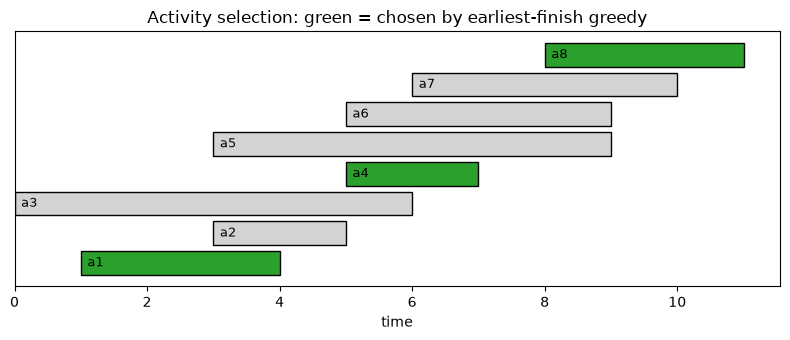

In [5]:
# Visualise: every activity as a bar; chosen ones highlighted
chosen_names = {a[0] for a in sel}
fig, ax = plt.subplots(figsize=(8, 3.5))
for row, (name, s, f) in enumerate(sorted(acts, key=lambda a: a[2])):
    colour = "tab:green" if name in chosen_names else "lightgray"
    ax.barh(row, f - s, left=s, color=colour, edgecolor="black")
    ax.text(s + 0.1, row, name, va="center", fontsize=9)
ax.set_yticks([])
ax.set_xlabel("time")
ax.set_title("Activity selection: green = chosen by earliest-finish greedy")
plt.tight_layout()
plt.show()

**What just happened?** Greedy chose {a1, a4, a8}, and the random tests confirm that earliest-finish greedy always matches the brute-force maximum.

**Complexity:** O(n log n) time for the sort plus O(n) for the scan; O(n) space for the sorted copy (O(1) extra if you sort in place).

> ⚠️ **Common mistake:** sorting by **start time** or by **shortest duration** is wrong. Counterexamples: start-time order picks one long early activity that blocks everything; shortest-first picks a short activity that overlaps two longer, compatible ones, e.g. (0,5), (4,7), (6,11) where shortest-first picks (4,7) only.

## 5. Fractional knapsack

> 💡 **In plain English:** if you may take part of an item (like gold dust), filling the bag with the most valuable-per-kilo stuff first is always best.

Same as knapsack, but you may take **any fraction** of an item (think gold dust, not gold bars). Greedy by value/weight is now **optimal**: whatever capacity you fill, filling it with the densest material available can only help (exchange argument: if an optimal solution uses some weight of a less dense item while a denser item is not fully used, swapping that weight increases or keeps the value).

With the CLRS items and `W = 50`: take all of A (10 kg, 60), all of B (20 kg, 100), then 20/30 of C (value 80). Total **240**.

To check the greedy result independently, note that with integer weights we can cut every item into 1-kg pieces worth `value/weight` each and solve a bounded knapsack over those pieces with dynamic programming.

In [6]:
def fractional_knapsack(items, W):
    """items: (name, weight, value). Returns (best value, list of (name, fraction taken))."""
    total = 0.0
    taken = []
    for name, w, v in sorted(items, key=lambda it: it[2] / it[1], reverse=True):  # densest first
        if W == 0:
            break
        amount = min(w, W)                    # all of it, or whatever still fits
        total += v * amount / w               # proportional value
        taken.append((name, amount / w))
        W -= amount
    return total, taken


def dp_unit_pieces(items, W):
    """Independent checker: split each item into 1-unit pieces and run a 0/1 DP over pieces."""
    best = [0.0] * (W + 1)                    # best[c] = max value with capacity c
    for _, w, v in items:
        for _piece in range(w):               # w pieces, each weight 1, value v/w
            for c in range(W, 0, -1):
                best[c] = max(best[c], best[c - 1] + v / w)
    return best[W]


print(fractional_knapsack(items, 50))
for trial in range(200):
    its = [(i, random.randint(1, 8), random.randint(1, 40)) for i in range(random.randint(1, 6))]
    W = random.randint(0, 25)
    assert abs(fractional_knapsack(its, W)[0] - dp_unit_pieces(its, W)) < 1e-9
print("fractional knapsack greedy matches the unit-piece DP on 200 random instances")

(240.0, [('A', 1.0), ('B', 1.0), ('C', 0.6666666666666666)])
fractional knapsack greedy matches the unit-piece DP on 200 random instances


**What just happened?** Greedy took A and B whole and two thirds of C for a total of 240, and matched an independent DP on 200 random instances.

**Complexity:** O(n log n) for sorting by ratio, O(1) extra space. (It can even be done in O(n) with a linear-time weighted-median selection, a classic exam extension.)

## 6. Job sequencing with deadlines

> 💡 **In plain English:** to earn the most from one-hour jobs with deadlines, handle the best-paying jobs first and put each one as late as its deadline allows.

**Problem.** Each job takes **one unit of time**, has a **deadline** `d` (it must finish by time `d`) and a **profit** earned only if it finishes on time. One machine. Choose and order jobs to maximise total profit.

**Greedy rule:** consider jobs from **highest profit to lowest**; put each job in the **latest free time slot not after its deadline** (leaving earlier slots open for jobs with tighter deadlines). If no slot is free, skip it.

Worked example:

| Job | J1 | J2 | J3 | J4 | J5 |
|---|---|---|---|---|---|
| deadline | 2 | 1 | 2 | 1 | 3 |
| profit | 100 | 19 | 27 | 25 | 15 |

Trace: J1 (100) → slot 2. J3 (27) → slot 2 taken, slot 1 free → slot 1. J4 (25) → slot 1 taken, skip. J2 (19) → skip. J5 (15) → slot 3. Schedule: J3, J1, J5 with profit **142**.

Why it works: the feasible job sets form a structure called a **matroid**, and on any matroid "take the heaviest element that keeps the set feasible" is optimal (this is the general theory behind Kruskal's algorithm too).

In [7]:
def job_sequencing(jobs):
    """jobs: list of (name, deadline, profit). Returns (profit, schedule list by time slot)."""
    max_d = max((d for _, d, _ in jobs), default=0)
    slot = [None] * (max_d + 1)                         # slot[t] = job that runs in (t-1, t]; slot[0] unused
    total = 0
    for name, d, p in sorted(jobs, key=lambda j: j[2], reverse=True):  # most profitable first
        for t in range(d, 0, -1):                        # latest free slot <= deadline
            if slot[t] is None:
                slot[t] = name
                total += p
                break
    return total, [s for s in slot[1:] if s is not None]


def brute_jobs(jobs):
    """Best profit over all feasible subsets. A set is feasible iff, sorted by deadline,
    the i-th job (1-based) has deadline >= i."""
    best = 0
    for r in range(len(jobs) + 1):
        for sub in itertools.combinations(jobs, r):
            ds = sorted(j[1] for j in sub)
            if all(ds[i] >= i + 1 for i in range(len(ds))):
                best = max(best, sum(j[2] for j in sub))
    return best


jobs = [("J1", 2, 100), ("J2", 1, 19), ("J3", 2, 27), ("J4", 1, 25), ("J5", 3, 15)]
print(job_sequencing(jobs))
for trial in range(300):
    js = [(f"j{i}", random.randint(1, 5), random.randint(1, 50)) for i in range(random.randint(0, 8))]
    assert job_sequencing(js)[0] == brute_jobs(js)
print("job sequencing matches brute force on 300 random instances")

(142, ['J3', 'J1', 'J5'])


job sequencing matches brute force on 300 random instances


**What just happened?** The schedule is J3, J1, J5 with profit 142, as in the hand trace, and greedy matched brute force on 300 random instances.

**Complexity:** sorting is O(n log n); the slot search is O(n · d_max) in the worst case, i.e. O(n²). Using a **disjoint-set union** ("which is the latest free slot ≤ t?") brings the scan down to almost O(n), so O(n log n) overall.

## 7. Minimum number of platforms

> 💡 **In plain English:** a station needs as many platforms as the largest number of trains standing there at the same moment.

**Problem.** Given arrival and departure times of trains at a station, find the minimum number of platforms so that no train waits. Convention used here (and in most textbooks): a train occupies its platform on the **closed** interval `[arrival, departure]`, so if one train departs at 9:10 and another arrives at 9:10, they need **two** platforms.

**Greedy / sweep-line idea:** sort the arrivals and the departures separately and walk through time. Each arrival needs a platform (+1), each departure frees one (−1). The answer is the maximum number in use at any moment. This equals the maximum number of intervals overlapping at one point (the **depth** of the interval set).

Worked example (times as HHMM):

| Train | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| arrival | 900 | 940 | 950 | 1100 | 1500 | 1800 |
| departure | 910 | 1200 | 1120 | 1130 | 1900 | 2000 |

Between 11:00 and 11:20 trains 2, 3 and 4 are all at the station, so we need **3** platforms.

In [8]:
def min_platforms(arr, dep):
    """Two-pointer sweep over sorted arrival and departure times."""
    arr, dep = sorted(arr), sorted(dep)
    i = j = 0
    in_use = best = 0
    while i < len(arr):
        if arr[i] <= dep[j]:          # next event is an arrival (ties: arrival first => closed intervals)
            in_use += 1
            best = max(best, in_use)
            i += 1
        else:                         # next event is a departure
            in_use -= 1
            j += 1
    return best


def brute_platforms(arr, dep):
    """Maximum overlap is reached at some arrival time: count trains present then."""
    return max((sum(a <= t <= d for a, d in zip(arr, dep)) for t in arr), default=0)


arr = [900, 940, 950, 1100, 1500, 1800]
dep = [910, 1200, 1120, 1130, 1900, 2000]
print("platforms needed:", min_platforms(arr, dep))
for trial in range(500):
    n = random.randint(1, 12)
    a = [random.randint(0, 50) for _ in range(n)]
    d = [x + random.randint(0, 15) for x in a]
    assert min_platforms(a, d) == brute_platforms(a, d)
print("min_platforms matches brute force on 500 random instances")

platforms needed: 3
min_platforms matches brute force on 500 random instances


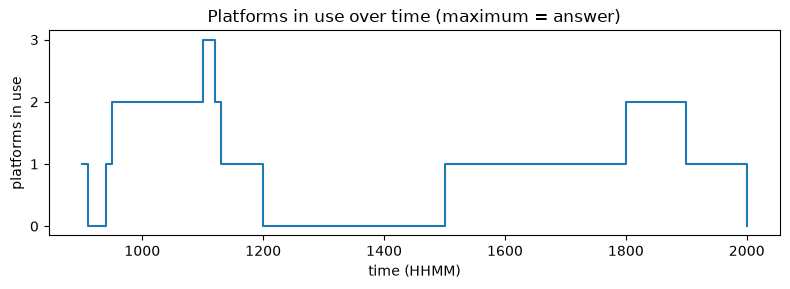

In [9]:
# Plot the number of platforms in use over the day
events = sorted([(a, +1) for a in arr] + [(d, -1) for d in dep], key=lambda e: (e[0], -e[1]))
times, counts, c = [], [], 0
for t, delta in events:
    c += delta
    times.append(t); counts.append(c)
fig, ax = plt.subplots(figsize=(8, 3))
ax.step(times, counts, where="post")
ax.set_xlabel("time (HHMM)"); ax.set_ylabel("platforms in use"); ax.set_yticks(range(max(counts) + 1))
ax.set_title("Platforms in use over time (maximum = answer)")
plt.tight_layout(); plt.show()

**What just happened?** The sweep found 3 platforms, the step plot peaks at 3 between 11:00 and 11:20, and the sweep matched brute force on 500 random cases.

**Complexity:** O(n log n) time (two sorts, then a linear sweep), O(n) space.

## 8. Huffman coding

> 💡 **In plain English:** Huffman coding gives frequent letters short codes and rare letters long ones, so the whole text needs fewer bits.

**Analogy:** Morse code gives the most common English letter, E, the shortest signal (a single dot). Huffman coding does the same for any text, and does it *optimally*.

A **prefix code** assigns each symbol a bit string such that no codeword is a prefix of another, so a bit stream can be decoded left to right without separators. Prefix codes correspond to binary trees: left edge = `0`, right edge = `1`, symbols at the leaves. **Huffman's algorithm** (1952) builds the prefix code that minimises the total encoded length `Σ freq(s) · len(code(s))`.

**Greedy rule:** put every symbol in a min-priority queue keyed by frequency. Repeatedly **remove the two least frequent nodes**, make them children of a new node whose frequency is their sum, and push it back. When one node remains, it is the root.

Worked example with frequencies `a:5, b:9, c:12, d:13, e:16, f:45` (CLRS):

```
step 1: merge a(5)  + b(9)   -> 14
step 2: merge c(12) + d(13)  -> 25
step 3: merge 14    + e(16)  -> 30
step 4: merge 25    + 30     -> 55
step 5: merge f(45) + 55     -> 100  (root)
```

Resulting code lengths: f = 1 bit, c, d, e = 3 bits, a, b = 4 bits. Cost = 45·1 + (12+13+16)·3 + (5+9)·4 = 45 + 123 + 56 = **224 bits**, versus 300 bits for a fixed 3-bit code.

**Why greedy is right (exchange argument):** in some optimal tree the two least frequent symbols are siblings at the deepest level (swapping a deeper, more frequent symbol with a shallower, less frequent one never increases the cost). Merging them gives a smaller instance of the same problem (optimal substructure).

In [10]:
class HNode:
    """A node of the Huffman tree. Leaves have a symbol; internal nodes have two children."""
    def __init__(self, freq, symbol=None, left=None, right=None):
        self.freq, self.symbol, self.left, self.right = freq, symbol, left, right


def build_huffman(freqs):
    """freqs: dict symbol -> count. Returns (root, merge log)."""
    tie = itertools.count()                       # tie-breaker so heapq never compares HNodes
    heap = [(f, next(tie), HNode(f, s)) for s, f in sorted(freqs.items())]
    heapq.heapify(heap)
    log = []
    if len(heap) == 1:                            # edge case: only one distinct symbol
        f, _, only = heap[0]
        return HNode(f, left=only), log
    while len(heap) > 1:
        f1, _, n1 = heapq.heappop(heap)           # least frequent
        f2, _, n2 = heapq.heappop(heap)           # second least frequent
        parent = HNode(f1 + f2, left=n1, right=n2)
        log.append((f1, f2, f1 + f2))
        heapq.heappush(heap, (parent.freq, next(tie), parent))
    return heap[0][2], log


def make_codes(node, prefix="", table=None):
    """Walk the tree: left = '0', right = '1'. Returns dict symbol -> codeword."""
    table = {} if table is None else table
    if node.symbol is not None:                   # leaf
        table[node.symbol] = prefix or "0"
    else:
        if node.left:  make_codes(node.left, prefix + "0", table)
        if node.right: make_codes(node.right, prefix + "1", table)
    return table


def encode(text, codes):
    return "".join(codes[ch] for ch in text)


def decode(bits, root):
    out, node = [], root
    for b in bits:
        node = node.left if b == "0" else node.right   # walk down one edge
        if node.symbol is not None:                    # reached a leaf: emit and restart
            out.append(node.symbol)
            node = root
    return "".join(out)


clrs = {"a": 5, "b": 9, "c": 12, "d": 13, "e": 16, "f": 45}
root, log = build_huffman(clrs)
codes = make_codes(root)
print("merges (f1, f2, sum):", log)
print(pd.DataFrame({"freq": clrs, "code": codes, "length": {s: len(c) for s, c in codes.items()}}))
print("total cost:", sum(clrs[s] * len(codes[s]) for s in clrs), "bits")

merges (f1, f2, sum): [(5, 9, 14), (12, 13, 25), (14, 16, 30), (25, 30, 55), (45, 55, 100)]
   freq  code  length
a     5  1100       4
b     9  1101       4
c    12   100       3
d    13   101       3
e    16   111       3
f    45     0       1
total cost: 224 bits


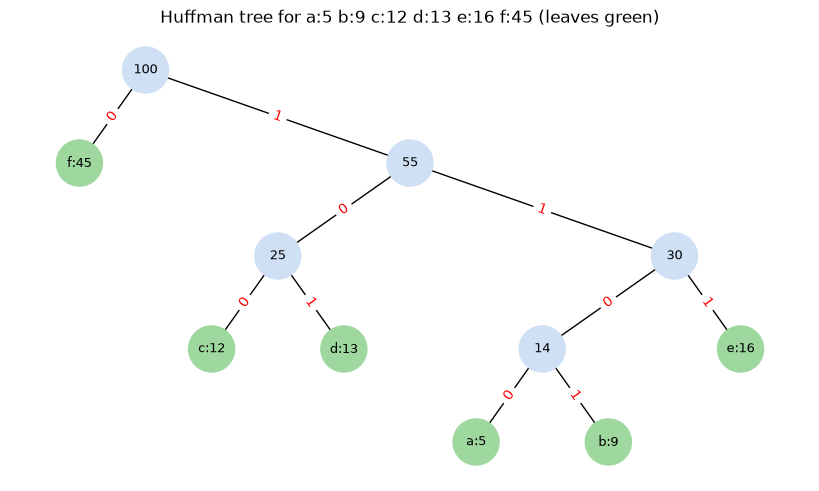

In [11]:
def draw_huffman(root, title):
    """Draw the tree with networkx using a simple layered layout (x = in-order position)."""
    G, pos, labels, edge_labels = nx.DiGraph(), {}, {}, {}
    counter = itertools.count()
    def walk(node, depth):
        if node is None:
            return None
        left = walk(node.left, depth + 1)
        me = id(node)
        pos[me] = (next(counter), -depth)          # in-order x keeps children either side of parent
        right = walk(node.right, depth + 1)
        labels[me] = f"{node.symbol}:{node.freq}" if node.symbol is not None else str(node.freq)
        G.add_node(me)
        for child, bit in ((left, "0"), (right, "1")):
            if child is not None:
                G.add_edge(me, child); edge_labels[(me, child)] = bit
        return me
    walk(root, 0)
    leaves = [n for n in G if G.out_degree(n) == 0]
    colours = ["#9fd89f" if n in leaves else "#cfe0f5" for n in G]
    plt.figure(figsize=(8, 4.5))
    nx.draw(G, pos, labels=labels, node_color=colours, node_size=1100, font_size=9, arrows=False)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color="red")
    plt.title(title); plt.show()

draw_huffman(root, "Huffman tree for a:5 b:9 c:12 d:13 e:16 f:45 (leaves green)")

**What just happened?** The merge log reproduces the five hand steps, `f` gets a 1-bit code, `a` and `b` get 4-bit codes, and the total cost is 224 bits as computed by hand. In the drawing, read a codeword by following the red edge labels from the root to a leaf.

Now a real piece of text: encode, decode, and measure the **compression ratio** against 8-bit ASCII and against the best fixed-length code. We also compare with the **Shannon entropy** `H = −Σ p log₂ p`, the theoretical lower bound on average bits per symbol; Huffman is guaranteed to satisfy `H ≤ L < H + 1`.

In [12]:
text = "this is an example of a huffman tree and it compresses text by giving frequent letters short codes"
freqs = Counter(text)
root_t, _ = build_huffman(freqs)
codes_t = make_codes(root_t)
bits = encode(text, codes_t)
assert decode(bits, root_t) == text                         # lossless round trip

# Prefix-free check: no codeword is a prefix of another
cw = list(codes_t.values())
assert not any(a != b and b.startswith(a) for a in cw for b in cw)

n = len(text)
ascii_bits = 8 * n
fixed_bits = math.ceil(math.log2(len(freqs))) * n           # best fixed-length code for this alphabet
avg_len = len(bits) / n
H = -sum((f / n) * math.log2(f / n) for f in freqs.values())
print(f"characters: {n}, distinct symbols: {len(freqs)}")
print(f"ASCII: {ascii_bits} bits | fixed-length: {fixed_bits} bits | Huffman: {len(bits)} bits")
print(f"compression ratio vs ASCII: {ascii_bits / len(bits):.2f}x  ({100 * len(bits) / ascii_bits:.1f}% of original size)")
print(f"average bits/char: Huffman {avg_len:.3f}, entropy bound {H:.3f}")
assert H <= avg_len < H + 1
print("first 60 encoded bits:", bits[:60])

characters: 98, distinct symbols: 23
ASCII: 784 bits | fixed-length: 490 bits | Huffman: 402 bits
compression ratio vs ASCII: 1.95x  (51.3% of original size)
average bits/char: Huffman 4.102, entropy bound 4.054
first 60 encoded bits: 000011110100101111101001011111001101011111000010000111010011


How do we know Huffman is truly *optimal* and not just good? For a small alphabet we can brute-force it: by the **Kraft inequality**, a prefix code with codeword lengths `l₁..l_k` exists **if and only if** `Σ 2^(−lᵢ) ≤ 1`. So the optimal cost is the minimum of `Σ fᵢ·lᵢ` over all length vectors satisfying Kraft.

In [13]:
def brute_optimal_prefix_cost(freq_list):
    """Minimum sum f_i * l_i over all codeword-length vectors satisfying Kraft's inequality."""
    k = len(freq_list)
    if k == 1:
        return freq_list[0]                          # one symbol still needs 1 bit
    best = math.inf
    for lengths in itertools.product(range(1, k), repeat=k):     # lengths 1..k-1 suffice
        if sum(2.0 ** -l for l in lengths) <= 1:
            best = min(best, sum(f * l for f, l in zip(freq_list, lengths)))
    return best


for trial in range(150):
    k = random.randint(1, 6)
    fr = {chr(97 + i): random.randint(1, 30) for i in range(k)}
    r, _ = build_huffman(fr)
    c = make_codes(r)
    huff_cost = sum(fr[s] * len(c[s]) for s in fr)
    assert huff_cost == brute_optimal_prefix_cost(list(fr.values()))
print("Huffman cost equals the brute-force optimum on 150 random alphabets (k <= 6)")

Huffman cost equals the brute-force optimum on 150 random alphabets (k <= 6)


**What just happened?** The text round-trips exactly, the code is prefix-free, the average code length sits between the entropy `H` and `H + 1`, and on 150 random small alphabets Huffman's cost equals the brute-force optimum over **all** prefix codes.

**Complexity:** with a binary heap, building the tree for `k` distinct symbols is O(k log k) (k−1 merges, each O(log k)); encoding/decoding a text of length `n` is O(total bits).

> 🎓 **Exam / interview tip:** Huffman codes are not unique (ties and left/right choices can differ), but every Huffman code has the same, optimal, total cost. Do not mark a different-looking code as wrong without comparing costs.

## 9. Minimum coins for canonical coin systems

> 💡 **In plain English:** real coin systems are designed so that "biggest coin first" always gives the fewest coins; we test which systems have that property.

A coin system is **canonical** if the largest-coin-first greedy gives the minimum number of coins for **every** amount. Real currencies are designed to be canonical. For example, US coins {1, 5, 10, 25}, euro cents {1, 2, 5, 10, 20, 50, 100, 200} and Indian rupee denominations {1, 2, 5, 10, 20, 50, 100, 200, 500} are all canonical. {1, 3, 4} and {1, 7, 10} are not.

**How to test a system without checking infinitely many amounts:** Kozen and Zaks (1994) proved that if a system `c₁ = 1 < c₂ < … < c_n` is not canonical, the **smallest counterexample** is below `c_{n−1} + c_n`. So checking every amount up to that bound against the DP answer decides it.

In [14]:
def smallest_counterexample(coins):
    """Return the smallest amount where greedy is not optimal, or None if the system is canonical."""
    coins = sorted(coins)
    bound = coins[-1] + coins[-2] if len(coins) >= 2 else 1
    best = [0] + [math.inf] * bound
    for a in range(1, bound + 1):                       # one DP table up to the bound
        best[a] = min(best[a - c] + 1 for c in coins if c <= a)
        if len(greedy_coins(a, coins)) > best[a]:
            return a
    return None


systems = {
    "US cents {1,5,10,25}": [1, 5, 10, 25],
    "euro cents {1,2,5,...,200}": [1, 2, 5, 10, 20, 50, 100, 200],
    "Indian rupees {1,2,5,...,500}": [1, 2, 5, 10, 20, 50, 100, 200, 500],
    "{1,3,4}": [1, 3, 4],
    "{1,7,10}": [1, 7, 10],
    "{1,5,12}": [1, 5, 12],
}
rows = [{"coin system": name, "smallest counterexample": smallest_counterexample(c) or "none: canonical"}
        for name, c in systems.items()]
print(pd.DataFrame(rows).to_string(index=False))

# Double-check the canonical ones on every amount up to 1000
for name, c in systems.items():
    canon = smallest_counterexample(c) is None
    all_ok = all(len(greedy_coins(a, c)) == optimal_coins(a, c) for a in range(1, 1001))
    assert canon == all_ok, name
print("Kozen-Zaks bound agrees with an exhaustive check up to 1000 for every system")

                  coin system smallest counterexample
         US cents {1,5,10,25}         none: canonical
   euro cents {1,2,5,...,200}         none: canonical
Indian rupees {1,2,5,...,500}         none: canonical
                      {1,3,4}                       6
                     {1,7,10}                      14
                     {1,5,12}                      15


Kozen-Zaks bound agrees with an exhaustive check up to 1000 for every system


**What just happened?** The three real currencies have no counterexample (canonical), while {1, 3, 4} first fails at 6, {1, 7, 10} at 14 (greedy 10+1+1+1+1 = 5 coins vs. 7+7 = 2) and {1, 5, 12} at 15 (greedy 12+1+1+1 = 4 coins vs. 5+5+5 = 3). An exhaustive check up to 1000 agrees with the Kozen-Zaks test every time.

**Complexity:** greedy change for amount `A` with `n` coin types is O(n + number of coins returned), or O(n) using division instead of repeated subtraction. The DP is O(n · A).

## 10. Greedy graph algorithms you already know

> 💡 **In plain English:** three famous network algorithms (Kruskal, Prim, Dijkstra) are greedy, and Dijkstra goes wrong if a road can have a negative length.

Three famous graph algorithms from [`07_graphs.ipynb`](07_graphs.ipynb) are greedy:

| Algorithm | Greedy choice at each step | Why the choice is safe | Time (binary heap) |
|---|---|---|---|
| **Kruskal** (MST) | add the cheapest edge that does not create a cycle | **cut property**: the lightest edge crossing any cut belongs to some MST (exchange argument) | O(E log E) |
| **Prim** (MST) | add the cheapest edge leaving the current tree | the same cut property, applied to the cut (tree, rest) | O(E log V) |
| **Dijkstra** (shortest paths) | finalise the unvisited vertex with the smallest tentative distance | with **non-negative** weights, no later path can come back cheaper | O((V + E) log V) |

Dijkstra's greedy choice relies on non-negative edge weights. With one negative edge, the greedy "finalise the closest vertex" step can be wrong. A 3-vertex demonstration, checked against Bellman-Ford (a DP-style algorithm):

In [15]:
def dijkstra(graph, src):
    """Textbook Dijkstra: once a vertex is popped, its distance is final (greedy)."""
    dist = {v: math.inf for v in graph}
    dist[src] = 0
    done = set()
    pq = [(0, src)]
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)                                  # greedy commitment
        for v, w in graph[u]:
            if v not in done and d + w < dist[v]:    # never revisits finalised vertices
                dist[v] = d + w
                heapq.heappush(pq, (dist[v], v))
    return dist


def bellman_ford(graph, src):
    """Relax every edge V-1 times: correct with negative edges (no negative cycles)."""
    dist = {v: math.inf for v in graph}
    dist[src] = 0
    for _ in range(len(graph) - 1):
        for u in graph:
            for v, w in graph[u]:
                if dist[u] + w < dist[v]:
                    dist[v] = dist[u] + w
    return dist


g = {"S": [("A", 2), ("B", 5)], "A": [], "B": [("A", -4)]}   # S->A costs 2 directly, or 5-4 = 1 via B
print("Dijkstra    :", dijkstra(g, "S"))
print("Bellman-Ford:", bellman_ford(g, "S"))

Dijkstra    : {'S': 0, 'A': 2, 'B': 5}
Bellman-Ford: {'S': 0, 'A': 1, 'B': 5}


**What just happened?** Dijkstra finalised `A` at distance 2 because it was the closest vertex when popped, and never revisited it. Bellman-Ford finds the true distance 1 via `S → B → A`. Lesson: a greedy algorithm is only as good as the property that justifies its choice.

---
# Part B: Divide and conquer

## 11. The paradigm and the master theorem

> 💡 **In plain English:** divide and conquer splits a problem into smaller copies, solves them and joins the answers; the master theorem tells you how fast that is.

**Analogy:** to count the people in a stadium, split it into sections, have one helper count each section, then add up the totals.

**Divide and conquer (D&C)** solves a problem in three steps:

1. **Divide** the input into smaller subproblems of the same type (usually halves).
2. **Conquer** each subproblem recursively (solve tiny ones directly: the **base case**).
3. **Combine** the sub-answers into the answer for the whole.

The running time satisfies a **recurrence** `T(n) = a·T(n/b) + f(n)`: `a` subproblems of size `n/b`, plus `f(n)` work to divide and combine. The **master theorem** compares `f(n)` with `n^(log_b a)`:

| Case | Condition | Result | Example |
|---|---|---|---|
| 1 | `f(n) = O(n^(log_b a − ε))` (combine is cheap) | `T(n) = Θ(n^(log_b a))` | Karatsuba: `3T(n/2) + O(n)` → Θ(n^1.585) |
| 2 | `f(n) = Θ(n^(log_b a))` (balanced) | `T(n) = Θ(n^(log_b a) · log n)` | merge sort: `2T(n/2) + Θ(n)` → Θ(n log n) |
| 3 | `f(n) = Ω(n^(log_b a + ε))` and regularity | `T(n) = Θ(f(n))` | `2T(n/2) + Θ(n²)` → Θ(n²) |

Binary search `T(n) = T(n/2) + O(1)` is case 2 with `log_b a = 0`, giving Θ(log n).

**D&C vs. DP:** D&C subproblems are **independent** (the two halves of a merge sort never share work). When subproblems **overlap**, plain D&C recomputes them, and dynamic programming (notebook 09) is the fix.

## 12. Merge sort and quicksort (recap)

> 💡 **In plain English:** merge sort and quicksort are the classic examples of splitting a list, sorting the pieces and putting them back together.

Both are covered in detail in the sorting notebook of this module ([`03_searching_and_sorting.ipynb`](03_searching_and_sorting.ipynb)); here we look at them as D&C templates.

| | Divide | Conquer | Combine | Time | Extra space | Stable? |
|---|---|---|---|---|---|---|
| **Merge sort** | split in the middle (trivial) | sort both halves | **merge** two sorted lists (the real work, Θ(n)) | Θ(n log n) always | Θ(n) | yes |
| **Quicksort** | **partition** around a pivot (the real work, Θ(n)) | sort both sides | nothing | Θ(n log n) average, Θ(n²) worst | Θ(log n) stack on average | no (usual in-place version) |

In [16]:
def merge(left, right):
    """Merge two sorted lists into one sorted list in linear time."""
    out, i, j = [], 0, 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:            # <= keeps equal elements in order (stable)
            out.append(left[i]); i += 1
        else:
            out.append(right[j]); j += 1
    return out + left[i:] + right[j:]      # one of these is empty


def merge_sort(a, depth=0, trace=None):
    if trace is not None:
        trace.append("    " * depth + f"split {a}")
    if len(a) <= 1:                        # base case
        return a
    mid = len(a) // 2
    result = merge(merge_sort(a[:mid], depth + 1, trace), merge_sort(a[mid:], depth + 1, trace))
    if trace is not None:
        trace.append("    " * depth + f"merged -> {result}")
    return result


def quicksort(a):
    """Randomised quicksort (out-of-place version for clarity)."""
    if len(a) <= 1:
        return a
    pivot = random.choice(a)               # random pivot makes the Θ(n²) worst case very unlikely
    less = [x for x in a if x < pivot]
    equal = [x for x in a if x == pivot]   # three-way split handles duplicates well
    greater = [x for x in a if x > pivot]
    return quicksort(less) + equal + quicksort(greater)


trace = []
print(merge_sort([38, 27, 43, 3, 9, 82, 10], trace=trace))
print("\n".join(trace))
for trial in range(300):
    arr_ = [random.randint(-50, 50) for _ in range(random.randint(0, 40))]
    assert merge_sort(arr_) == quicksort(arr_) == sorted(arr_)
print("merge_sort and quicksort match sorted() on 300 random lists")

[3, 9, 10, 27, 38, 43, 82]
split [38, 27, 43, 3, 9, 82, 10]
    split [38, 27, 43]
        split [38]
        split [27, 43]
            split [27]
            split [43]
        merged -> [27, 43]
    merged -> [27, 38, 43]
    split [3, 9, 82, 10]
        split [3, 9]
            split [3]
            split [9]
        merged -> [3, 9]
        split [82, 10]
            split [82]
            split [10]
        merged -> [10, 82]
    merged -> [3, 9, 10, 82]
merged -> [3, 9, 10, 27, 38, 43, 82]


merge_sort and quicksort match sorted() on 300 random lists


**What just happened?** The indented trace shows the recursion: the list is split down to single elements (base case), then merged back up level by level. There are about log₂ n levels and each level does Θ(n) merging work in total, which is where Θ(n log n) comes from.

## 13. Counting inversions

> 💡 **In plain English:** an inversion is a pair of items in the wrong order; we count them quickly by riding along with merge sort.

An **inversion** in an array is a pair of positions `i < j` with `a[i] > a[j]`. The count measures how far the array is from sorted: 0 for sorted, `n(n−1)/2` for reverse-sorted. It is used to compare two rankings (the **Kendall tau distance** between two rankings is the number of inversions): "how similar are my top-10 movie list and yours?"

Brute force checks all pairs: Θ(n²). **D&C idea:** inversions = (inside the left half) + (inside the right half) + (**split inversions**, one element in each half). While merging, whenever we take an element from the **right** half, it is smaller than every element still waiting in the left half, so it forms `len(left) − i` split inversions at once.

Worked example: `[2, 4, 1, 3, 5]` has inversions (2,1), (4,1), (4,3), so the count is **3**.

In [17]:
def count_inversions(a):
    """Returns (sorted copy, number of inversions) in O(n log n)."""
    if len(a) <= 1:
        return a, 0
    mid = len(a) // 2
    left, inv_l = count_inversions(a[:mid])
    right, inv_r = count_inversions(a[mid:])
    merged, i, j, split = [], 0, 0, 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            merged.append(left[i]); i += 1
        else:
            merged.append(right[j]); j += 1
            split += len(left) - i            # right[j] is smaller than all remaining left elements
    merged += left[i:] + right[j:]
    return merged, inv_l + inv_r + split


def brute_inversions(a):
    return sum(1 for i in range(len(a)) for j in range(i + 1, len(a)) if a[i] > a[j])


print(count_inversions([2, 4, 1, 3, 5])[1])
for trial in range(300):
    arr_ = [random.randint(0, 20) for _ in range(random.randint(0, 50))]
    assert count_inversions(arr_)[1] == brute_inversions(arr_)
assert count_inversions(list(range(100, 0, -1)))[1] == 100 * 99 // 2
print("count_inversions matches brute force on 300 random lists (with duplicates)")

3


count_inversions matches brute force on 300 random lists (with duplicates)


**What just happened?** We got 3 for the worked example, matched the Θ(n²) checker on random lists with duplicates, and got `n(n−1)/2 = 4950` for a reversed list of 100.

**Complexity:** `T(n) = 2T(n/2) + Θ(n)` → Θ(n log n) time, Θ(n) extra space.

## 14. Maximum subarray: brute force vs. divide & conquer vs. Kadane

> 💡 **In plain English:** find the run of consecutive days with the biggest total profit, three ways, from slow to very fast.

**Problem.** Given numbers (some negative), find the contiguous, non-empty subarray with the largest sum. Example: daily profit/loss, find the best stretch of days.

Example: `[−2, 1, −3, 4, −1, 2, 1, −5, 4]` → best is `[4, −1, 2, 1]` with sum **6**.

| Method | Idea | Time |
|---|---|---|
| Brute force | try every (i, j), keep a running sum | Θ(n²) |
| **Divide & conquer** | best is entirely in the left half, entirely in the right half, or **crosses the middle**; the crossing one = best suffix of left + best prefix of right | Θ(n log n) |
| **Kadane** | scan once; `best_ending_here = max(x, best_ending_here + x)` | Θ(n) |

Kadane is really a tiny dynamic program (state = best sum ending at position i), which is why it beats D&C: it reuses the previous answer instead of recomputing across halves.

In [18]:
def max_subarray_brute(a):
    best = -math.inf
    for i in range(len(a)):
        s = 0
        for j in range(i, len(a)):
            s += a[j]                         # sum of a[i..j]
            best = max(best, s)
    return best


def max_subarray_dc(a, lo=0, hi=None):
    """Divide and conquer on a[lo:hi]."""
    if hi is None:
        hi = len(a)
    if hi - lo == 1:                          # base case: one element
        return a[lo]
    mid = (lo + hi) // 2
    best_left = max_subarray_dc(a, lo, mid)
    best_right = max_subarray_dc(a, mid, hi)
    s, best_suffix = 0, -math.inf             # best sum ending at mid-1, going left
    for i in range(mid - 1, lo - 1, -1):
        s += a[i]; best_suffix = max(best_suffix, s)
    s, best_prefix = 0, -math.inf             # best sum starting at mid, going right
    for j in range(mid, hi):
        s += a[j]; best_prefix = max(best_prefix, s)
    return max(best_left, best_right, best_suffix + best_prefix)


def kadane(a):
    best = cur = a[0]
    for x in a[1:]:
        cur = max(x, cur + x)                 # extend the previous run or start fresh at x
        best = max(best, cur)
    return best


ex = [-2, 1, -3, 4, -1, 2, 1, -5, 4]
print(max_subarray_brute(ex), max_subarray_dc(ex), kadane(ex))
for trial in range(500):
    arr_ = [random.randint(-20, 20) for _ in range(random.randint(1, 40))]
    assert max_subarray_brute(arr_) == max_subarray_dc(arr_) == kadane(arr_)
print("all three agree on 500 random arrays (including all-negative ones)")

6 6 6


all three agree on 500 random arrays (including all-negative ones)


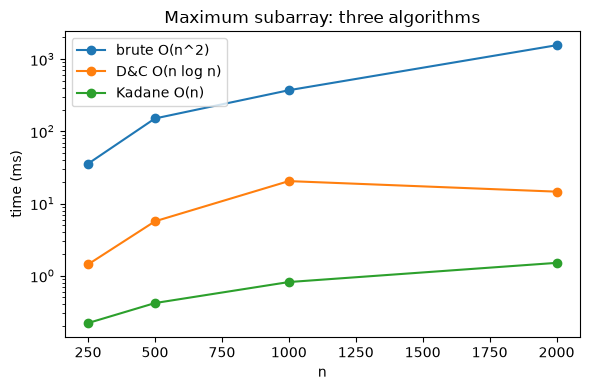

     brute O(n^2) D&C O(n log n) Kadane O(n)
250      35.64 ms        1.43 ms     0.22 ms
500     150.90 ms        5.68 ms     0.42 ms
1000    371.46 ms       20.47 ms     0.82 ms
2000   1560.11 ms       14.62 ms     1.51 ms


In [19]:
def best_time(fn, data, repeats=3):
    """Minimum wall time over a few repeats (less noisy than a single run)."""
    best = math.inf
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(data); best = min(best, time.perf_counter() - t0)
    return best

sizes = [250, 500, 1000, 2000]
timings = {"brute O(n^2)": [], "D&C O(n log n)": [], "Kadane O(n)": []}
for n in sizes:
    data = [random.randint(-100, 100) for _ in range(n)]
    timings["brute O(n^2)"].append(best_time(max_subarray_brute, data))
    timings["D&C O(n log n)"].append(best_time(max_subarray_dc, data))
    timings["Kadane O(n)"].append(best_time(kadane, data))

fig, ax = plt.subplots(figsize=(6, 4))
for label, ts in timings.items():
    ax.plot(sizes, [t * 1000 for t in ts], marker="o", label=label)
ax.set_xlabel("n"); ax.set_ylabel("time (ms)"); ax.set_yscale("log")
ax.set_title("Maximum subarray: three algorithms"); ax.legend()
plt.tight_layout(); plt.show()
print(pd.DataFrame({k: [f"{t*1000:.2f} ms" for t in v] for k, v in timings.items()}, index=sizes))

**What just happened?** All three methods agree, but their growth differs: doubling `n` roughly quadruples the brute-force time at the larger sizes, a little more than doubles the D&C time, and about doubles Kadane's (tiny inputs are noisy). (Exact milliseconds depend on your machine.)

## 15. Closest pair of points

> 💡 **In plain English:** to find the two closest points, split the points into a left and a right half and only check a thin strip near the dividing line.

**Problem.** Given `n` points in the plane, find the two with the smallest Euclidean distance. Brute force checks all `n(n−1)/2` pairs: Θ(n²). (Used in collision detection, clustering, and as the classic warm-up for nearest-neighbour data structures.)

**D&C algorithm (Shamos & Hoos, 1975), O(n log n):**

1. Sort the points by x once (and keep a copy sorted by y).
2. Split by the median x into left and right halves; recursively find the closest distances `δ_L`, `δ_R`; let `δ = min(δ_L, δ_R)`.
3. A closer pair would have to **cross** the dividing line, so both points lie in the vertical **strip** of width `2δ` around it.
4. Walk the strip in **y order**; each point only needs to be compared with the next few (at most 7) points above it, because a `δ × 2δ` rectangle can hold only 8 points that are pairwise at least `δ` apart.

```
        |<-- δ -->|<-- δ -->|
   .    |   .     |      .  |     .
        |      .  |  .      |
   .    |         | .       |  .
        |  strip of width 2δ around the median x
```

Because step 4 is linear and the y-sorted lists are split rather than re-sorted, `T(n) = 2T(n/2) + O(n)` = **O(n log n)**.

closest_pair matches brute force on 300 random point sets


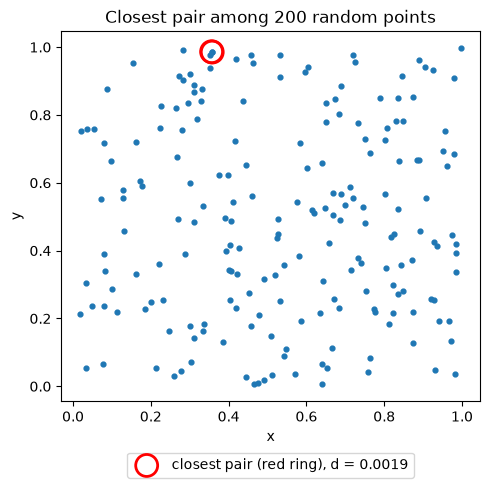

In [20]:
def dist(p, q):
    return math.hypot(p[0] - q[0], p[1] - q[1])


def closest_pair_brute(pts):
    best = (math.inf, None, None)
    for i in range(len(pts)):
        for j in range(i + 1, len(pts)):
            d = dist(pts[i], pts[j])
            if d < best[0]:
                best = (d, pts[i], pts[j])
    return best


def closest_pair(points):
    """O(n log n) closest pair. Returns (distance, p, q)."""
    tagged = [(x, y, i) for i, (x, y) in enumerate(points)]   # index tag handles duplicate points
    px = sorted(tagged)                                         # by x (then y)
    py = sorted(tagged, key=lambda p: (p[1], p[0]))             # by y
    d, p, q = _closest(px, py)
    return d, p[:2], q[:2]


def _closest(px, py):
    n = len(px)
    if n <= 3:                                                  # base case: brute force
        best = (math.inf, None, None)
        for i in range(n):
            for j in range(i + 1, n):
                d = dist(px[i], px[j])
                if d < best[0]:
                    best = (d, px[i], px[j])
        return best
    mid = n // 2
    x_mid = px[mid][0]
    left_ids = {p[2] for p in px[:mid]}
    py_left = [p for p in py if p[2] in left_ids]               # keep y order while splitting: O(n)
    py_right = [p for p in py if p[2] not in left_ids]
    best = min(_closest(px[:mid], py_left), _closest(px[mid:], py_right), key=lambda t: t[0])
    strip = [p for p in py if abs(p[0] - x_mid) < best[0]]      # candidates near the dividing line
    for i in range(len(strip)):
        for j in range(i + 1, min(i + 8, len(strip))):          # at most 7 neighbours above
            if strip[j][1] - strip[i][1] >= best[0]:
                break
            d = dist(strip[i], strip[j])
            if d < best[0]:
                best = (d, strip[i], strip[j])
    return best


for trial in range(300):
    n = random.randint(2, 60)
    pts = [(random.randint(0, 30), random.randint(0, 30)) for _ in range(n)]   # integer grid: many ties/duplicates
    assert abs(closest_pair(pts)[0] - closest_pair_brute(pts)[0]) < 1e-12
print("closest_pair matches brute force on 300 random point sets")

pts = [(random.random(), random.random()) for _ in range(200)]
d, p, q = closest_pair(pts)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*zip(*pts), s=12)
ax.scatter([p[0], q[0]], [p[1], q[1]], s=250, facecolors="none", edgecolors="red", linewidths=2,
           label=f"closest pair (red ring), d = {d:.4f}")
ax.set_title("Closest pair among 200 random points")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

In [21]:
sizes = [250, 500, 1000, 2000]
t_brute, t_dc = [], []
for n in sizes:
    pts = [(random.random(), random.random()) for _ in range(n)]
    t_brute.append(best_time(closest_pair_brute, pts, repeats=1))
    t_dc.append(best_time(closest_pair, pts, repeats=1))
    assert abs(closest_pair(pts)[0] - closest_pair_brute(pts)[0]) < 1e-12
print(pd.DataFrame({"brute O(n^2)": [f"{t*1000:.1f} ms" for t in t_brute],
                    "D&C O(n log n)": [f"{t*1000:.1f} ms" for t in t_dc],
                    "speed-up": [f"{b/d:.1f}x" for b, d in zip(t_brute, t_dc)]}, index=sizes))

     brute O(n^2) D&C O(n log n) speed-up
250       35.1 ms         2.8 ms    12.7x
500      220.0 ms        26.9 ms     8.2x
1000     365.6 ms        35.1 ms    10.4x
2000    2498.1 ms        72.1 ms    34.6x


**What just happened?** The D&C version matches brute force on 300 random point sets (integer coordinates force many ties and duplicate points, the usual source of bugs), and the speed-up over brute force grows with `n`, as Θ(n²) vs. Θ(n log n) predicts.

> ⚠️ **Common mistake:** re-sorting the strip by y inside every call makes the algorithm O(n log² n). Pre-sorting by y once and splitting that list, as above, keeps it O(n log n).

## 16. Karatsuba multiplication

> 💡 **In plain English:** Karatsuba multiplies big numbers with 3 half-size multiplications instead of 4, and that saving adds up to a lot.

Schoolbook multiplication of two `n`-digit numbers multiplies every digit by every digit: Θ(n²) digit multiplications. In 1960 Anatoly Karatsuba found a D&C trick. Split each number in half (base 10, `m` = half the digits):

```
x = a·10^m + b        y = c·10^m + d
x·y = ac·10^(2m) + (ad + bc)·10^m + bd
```

That needs four half-size products (ac, ad, bc, bd), which gives `T(n) = 4T(n/2) + O(n)` = Θ(n²): no gain. Karatsuba's insight: `ad + bc = (a + b)(c + d) − ac − bd`, so **three** products are enough:

`T(n) = 3T(n/2) + O(n)` = Θ(n^(log₂ 3)) ≈ **Θ(n^1.585)**.

Worked example: `1234 × 5678`, `m = 2`: `a=12, b=34, c=56, d=78`. `ac = 672`, `bd = 2652`, `(a+b)(c+d) = 46·134 = 6164`, so `ad+bc = 6164 − 672 − 2652 = 2840`. Result `672·10⁴ + 2840·10² + 2652 = 7,006,652`.

CPython itself uses Karatsuba for multiplying very large integers.

In [22]:
single_digit_mults = 0      # counts base-case multiplications so we can compare with schoolbook

def karatsuba(x, y):
    global single_digit_mults
    if x < 0 or y < 0:                                  # handle signs, recurse on magnitudes
        sign = -1 if (x < 0) != (y < 0) else 1
        return sign * karatsuba(abs(x), abs(y))
    if x < 10 or y < 10:                                # base case: a single-digit factor
        single_digit_mults += 1
        return x * y
    m = max(len(str(x)), len(str(y))) // 2              # split position (number of low digits)
    a, b = divmod(x, 10 ** m)                           # x = a*10^m + b
    c, d = divmod(y, 10 ** m)                           # y = c*10^m + d
    ac = karatsuba(a, c)
    bd = karatsuba(b, d)
    mid = karatsuba(a + b, c + d) - ac - bd             # = ad + bc with one multiplication
    return ac * 10 ** (2 * m) + mid * 10 ** m + bd


print(karatsuba(1234, 5678))
for trial in range(500):
    x = random.randint(-10 ** 40, 10 ** 40); y = random.randint(-10 ** 40, 10 ** 40)
    assert karatsuba(x, y) == x * y
print("karatsuba matches Python's * on 500 random 40-digit numbers (with signs)")

rows = []
for digits in [2, 4, 8, 16, 32, 64, 128, 256]:
    x = random.randint(10 ** (digits - 1), 10 ** digits - 1)
    y = random.randint(10 ** (digits - 1), 10 ** digits - 1)
    single_digit_mults = 0
    karatsuba(x, y)
    rows.append({"digits n": digits, "schoolbook n^2": digits ** 2,
                 "Karatsuba base mults": single_digit_mults, "n^1.585": round(digits ** math.log2(3))})
print(pd.DataFrame(rows).to_string(index=False))

7006652


karatsuba matches Python's * on 500 random 40-digit numbers (with signs)
 digits n  schoolbook n^2  Karatsuba base mults  n^1.585
        2               4                     3        3
        4              16                    11        9
        8              64                    39       27
       16             256                   133       81
       32            1024                   343      243
       64            4096                  1001      729
      128           16384                  3205     2187
      256           65536                  9537     6561


**What just happened?** `1234 × 5678 = 7006652` as in the hand calculation, and the result matches Python on random signed 40-digit numbers. The table shows the base-case count growing roughly like `n^1.585` rather than `n²`: at 256 digits Karatsuba needs far fewer digit multiplications than the 65,536 of the schoolbook method. (Our count is a constant factor above the pure `n^1.585`, because `a + b` can carry an extra digit and odd lengths split unevenly; the growth rate is what matters.)

**Complexity:** Θ(n^log₂3) ≈ Θ(n^1.585) digit operations. In practice libraries switch to schoolbook below a cutoff size, because Karatsuba's additions and recursion cost more on small inputs.

## 17. Fast exponentiation (exponentiation by squaring)

> 💡 **In plain English:** to compute 3 to the power 13, keep squaring instead of multiplying 3 by itself 12 times.

Computing `xⁿ` by multiplying `x` by itself `n − 1` times is Θ(n) multiplications. D&C observation:

- `xⁿ = (x^(n/2))²` if `n` is even
- `xⁿ = x · (x^((n−1)/2))²` if `n` is odd

Each step halves `n`, so only **Θ(log n)** multiplications are needed. Example: `3¹³`: 13 = 1101 in binary, so `3¹³ = 3⁸ · 3⁴ · 3¹` and we only need the squares 3, 3², 3⁴, 3⁸.

With `% mod` after every multiplication, this is **modular exponentiation**, the workhorse of RSA and Diffie-Hellman cryptography. With 2×2 matrices it computes the n-th Fibonacci number in Θ(log n) matrix multiplications.

In [23]:
def power_recursive(x, n, mod=None):
    """x**n (mod mod) by recursive halving."""
    if n == 0:
        return 1 % mod if mod else 1
    half = power_recursive(x, n // 2, mod)
    result = half * half                         # one multiplication for the square
    if n % 2 == 1:
        result *= x                              # one more if n is odd
    return result % mod if mod else result


def power_iterative(x, n, mod=None):
    """Same idea, reading the bits of n from least significant to most significant."""
    result, base, mults = 1, x, 0
    while n > 0:
        if n & 1:                                # this bit is 1: include the current power of x
            result = result * base; mults += 1
            if mod: result %= mod
        base = base * base; mults += 1           # x, x^2, x^4, x^8, ...
        if mod: base %= mod
        n >>= 1
    return (result % mod if mod else result), mults


def mat_mult(A, B):
    return [[A[0][0]*B[0][0] + A[0][1]*B[1][0], A[0][0]*B[0][1] + A[0][1]*B[1][1]],
            [A[1][0]*B[0][0] + A[1][1]*B[1][0], A[1][0]*B[0][1] + A[1][1]*B[1][1]]]


def fib_matrix(n):
    """[[1,1],[1,0]]^n = [[F(n+1),F(n)],[F(n),F(n-1)]]."""
    result, base = [[1, 0], [0, 1]], [[1, 1], [1, 0]]
    while n > 0:
        if n & 1:
            result = mat_mult(result, base)
        base = mat_mult(base, base)
        n >>= 1
    return result[0][1]


print("3^13 =", power_recursive(3, 13), "| iterative:", power_iterative(3, 13))
for trial in range(500):
    x, n, m = random.randint(-50, 50), random.randint(0, 300), random.randint(2, 10 ** 9)
    assert power_recursive(x, n) == x ** n
    assert power_iterative(x, n, m)[0] == pow(x, n, m)
a, b = 0, 1
for k in range(200):
    assert fib_matrix(k) == a
    a, b = b, a + b
print("matches ** and pow(); fib_matrix matches the simple loop for n < 200")
print("multiplications for n = 1,000,000:", power_iterative(2, 10 ** 6, 10 ** 9 + 7)[1], "instead of 999,999")

3^13 = 1594323 | iterative: (1594323, 7)
matches ** and pow(); fib_matrix matches the simple loop for n < 200
multiplications for n = 1,000,000: 27 instead of 999,999


**What just happened?** `3¹³ = 1594323`; the iterative version used 7 multiplications. For `n = 1,000,000` it needs only 27 multiplications (20 squarings for the 20 bits, plus one per 1-bit), instead of 999,999.

**Complexity:** Θ(log n) multiplications; Θ(log n) stack space for the recursive version, Θ(1) for the iterative one.

## 18. Strassen's matrix multiplication (the idea)

> 💡 **In plain English:** Strassen multiplies matrices with 7 block multiplications instead of 8, and the saving grows at every level.

Multiplying two `n × n` matrices the usual way costs `n³` scalar multiplications. Split each matrix into four `n/2 × n/2` blocks:

```
| A11 A12 |   | B11 B12 |   | C11 C12 |
| A21 A22 | x | B21 B22 | = | C21 C22 |      C11 = A11·B11 + A12·B21, etc.
```

The block formula needs **8** block products → `T(n) = 8T(n/2) + O(n²)` = Θ(n³). In 1969 Volker Strassen found a way to use **7** block products (and more additions):

```
M1 = (A11 + A22)(B11 + B22)      C11 = M1 + M4 − M5 + M7
M2 = (A21 + A22) B11             C12 = M3 + M5
M3 = A11 (B12 − B22)             C21 = M2 + M4
M4 = A22 (B21 − B11)             C22 = M1 − M2 + M3 + M6
M5 = (A11 + A12) B22
M6 = (A21 − A11)(B11 + B12)
M7 = (A12 − A22)(B21 + B22)
```

`T(n) = 7T(n/2) + O(n²)` = Θ(n^(log₂ 7)) ≈ **Θ(n^2.807)**. Later research lowered the theoretical exponent further (below 2.372 as of 2024), but those algorithms are only faster for astronomically large matrices. In practice, numerical libraries (BLAS, the GPU kernels behind deep learning) use the cubic algorithm with excellent cache and hardware use, and Strassen-like variants only for very large matrices.

In [24]:
def strassen(A, B, cutoff=2):
    """Strassen multiplication for square matrices whose size is a power of two."""
    n = A.shape[0]
    if n <= cutoff:                                         # small: ordinary multiplication
        return A @ B
    h = n // 2
    A11, A12, A21, A22 = A[:h, :h], A[:h, h:], A[h:, :h], A[h:, h:]
    B11, B12, B21, B22 = B[:h, :h], B[:h, h:], B[h:, :h], B[h:, h:]
    M1 = strassen(A11 + A22, B11 + B22, cutoff)
    M2 = strassen(A21 + A22, B11, cutoff)
    M3 = strassen(A11, B12 - B22, cutoff)
    M4 = strassen(A22, B21 - B11, cutoff)
    M5 = strassen(A11 + A12, B22, cutoff)
    M6 = strassen(A21 - A11, B11 + B12, cutoff)
    M7 = strassen(A12 - A22, B21 + B22, cutoff)
    C = np.empty_like(A)
    C[:h, :h] = M1 + M4 - M5 + M7
    C[:h, h:] = M3 + M5
    C[h:, :h] = M2 + M4
    C[h:, h:] = M1 - M2 + M3 + M6
    return C


for n in [1, 2, 4, 8, 16, 32, 64]:
    A = np.random.randint(-9, 10, size=(n, n)).astype(np.int64)   # integers: exact comparison
    B = np.random.randint(-9, 10, size=(n, n)).astype(np.int64)
    assert np.array_equal(strassen(A, B), A @ B)
print("strassen matches numpy's A @ B exactly for n = 1 .. 64")
print(pd.DataFrame({"n": [2 ** k for k in range(1, 8)],
                    "block method 8^k": [8 ** k for k in range(1, 8)],
                    "Strassen 7^k": [7 ** k for k in range(1, 8)]}).to_string(index=False))

strassen matches numpy's A @ B exactly for n = 1 .. 64
  n  block method 8^k  Strassen 7^k
  2                 8             7
  4                64            49
  8               512           343
 16              4096          2401
 32             32768         16807
 64            262144        117649
128           2097152        823543


**What just happened?** Our Strassen implementation is exact on integer matrices up to 64 × 64. The table counts scalar multiplications when recursing all the way down to 1 × 1 blocks (`n = 2^k`): the 7-vs-8 saving compounds at every level, so at `n = 128` it is 823,543 vs. 2,097,152.

## 19. Greedy vs. divide & conquer vs. dynamic programming

> 💡 **In plain English:** a side-by-side table to help you choose greedy, divide and conquer, or dynamic programming for a new problem.

| | Greedy | Divide & conquer | Dynamic programming |
|---|---|---|---|
| Core move | commit to the locally best choice | split into **independent** subproblems, combine | solve **overlapping** subproblems once, store them |
| Needs | greedy-choice property + optimal substructure | a way to combine sub-answers | optimal substructure + overlapping subproblems |
| Reconsiders choices? | never | n/a | yes, implicitly compares all options |
| Typical cost | O(n log n) (sort + scan) | recurrence, master theorem | (number of states) × (work per state) |
| Correctness proof | exchange argument | induction on size | induction over the recurrence |
| Examples | activity selection, Huffman, Kruskal, Prim, Dijkstra, fractional knapsack | merge sort, quicksort, closest pair, Karatsuba, Strassen, FFT | 0/1 knapsack, coin change (any coins), LCS, edit distance, Bellman-Ford |

> 🎓 **Exam / interview tip:** a quick way to choose: first look for a greedy rule and try to break it with a tiny counterexample. If it breaks, check whether subproblems overlap (DP) or are independent (D&C).

## 20. 🔗 How this connects to modern AI

> 💡 **In plain English:** greedy and divide-and-conquer ideas hide inside chatbots, decision trees, tokenizers, zip files and distributed training.

- **Greedy decoding in language models.** Choosing the most probable next token at each step is a greedy algorithm, and it is *not* optimal for the whole sentence (a high-probability first word can lead to a low-probability continuation, just like the 4-coin above). Beam search keeps several candidates to soften this. See [`07_NLP/05_language_models_and_generation.ipynb`](../../07_NLP/05_language_models_and_generation.ipynb).
- **Decision trees** are grown greedily: each node picks the split with the best immediate impurity reduction, with no look-ahead. That is why trees can be sub-optimal and why ensembles help. See [`03_Machine_Learning/01_supervised/03_decision_trees.ipynb`](../../03_Machine_Learning/01_supervised/03_decision_trees.ipynb).
- **Tokenizers.** Byte-pair encoding (BPE), used by GPT-style tokenizers, greedily merges the most frequent adjacent pair of symbols, a close cousin of Huffman's "merge the two least frequent" step. Huffman coding itself lives on inside DEFLATE (zip, gzip, PNG) and JPEG. The entropy bound you checked above is covered in [`14_Mathematics/05_information_theory.ipynb`](../../14_Mathematics/05_information_theory.ipynb).
- **Forward feature selection** and many fast clustering/summarisation heuristics are greedy algorithms with approximation guarantees (e.g. greedily picking k items to maximise a monotone submodular function, such as coverage, achieves at least (1 − 1/e) ≈ 63% of the optimum).
- **Divide and conquer at scale.** MapReduce/Spark aggregation and distributed training (split the data or model, compute in parallel, combine gradients) follow the divide/conquer/combine pattern; see [`05_Deep_Learning/11_distributed_training.ipynb`](../../05_Deep_Learning/11_distributed_training.ipynb). KD-trees and ball trees for nearest-neighbour search (k-NN, retrieval) recursively split space just like the closest-pair algorithm; see [`03_Machine_Learning/01_supervised/07_knn.ipynb`](../../03_Machine_Learning/01_supervised/07_knn.ipynb).
- **Fast arithmetic.** The FFT (a D&C algorithm) powers convolution and audio processing; fast exponentiation is in every cryptographic library protecting model APIs; Strassen-style ideas inspired DeepMind's AlphaTensor (2022), which used reinforcement learning to discover new matrix-multiplication algorithms.
- **Ranking evaluation.** Counting inversions gives the Kendall tau distance between two rankings, used to compare search or recommendation rankings; see [`03_Machine_Learning/01_supervised/12_learning_to_rank.ipynb`](../../03_Machine_Learning/01_supervised/12_learning_to_rank.ipynb).

## 21. Recap

> 💡 **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- A **greedy algorithm** commits to the locally best choice. It is optimal only when the problem has the **greedy-choice property** and **optimal substructure**; prove it with an **exchange argument**, disprove it with a **small counterexample**.
- Greedy **fails** for coin change with {1, 3, 4} (6 = 3 + 3, not 4 + 1 + 1) and for 0/1 knapsack, but works for **fractional** knapsack and for **canonical** coin systems (test with the Kozen-Zaks bound `c_(n−1) + c_n`).
- Classic greedy problems: activity selection (earliest **finish** first), job sequencing (highest profit into the latest free slot), minimum platforms (sweep line), Huffman coding (merge the two rarest; `H ≤ L < H + 1`).
- Kruskal, Prim and Dijkstra are greedy; Dijkstra breaks with negative edges.
- **Divide and conquer** = divide, conquer, combine; analyse with `T(n) = aT(n/b) + f(n)` and the master theorem.
- Counting inversions and closest pair piggy-back on merge sort's structure for Θ(n log n); Karatsuba (3 products instead of 4) gives Θ(n^1.585); Strassen (7 instead of 8) gives Θ(n^2.807); fast exponentiation needs Θ(log n) multiplications.
- Kadane's Θ(n) maximum subarray beats the Θ(n log n) D&C version because it is really dynamic programming, which is the topic of the next notebook.

## Practice problems

**1. (Easy, conceptual)** Give a counterexample showing that, for activity selection, choosing the activity with the **earliest start time** first is not optimal.

<details><summary>Show solution</summary>

Activities (0, 10), (1, 2), (3, 4). Earliest start picks (0, 10), which overlaps both others: 1 activity. Optimal picks (1, 2) and (3, 4): 2 activities.
</details>

**2. (Easy, conceptual)** Is the coin system {1, 2, 5} canonical? Is {1, 6, 10}? Use the Kozen-Zaks bound.

<details><summary>Show solution</summary>

{1, 2, 5}: check amounts below 2 + 5 = 7; greedy is optimal for 1..6, so it is canonical.
{1, 6, 10}: check below 6 + 10 = 16; at 12 greedy gives 10 + 1 + 1 (3 coins) but 6 + 6 uses 2. Not canonical. (`smallest_counterexample([1, 6, 10])` returns 12.)
</details>

**3. (Medium, coding)** Write `max_meeting_rooms(intervals)` for half-open intervals `[start, end)` (a meeting ending at 10 frees the room for one starting at 10), using a min-heap of end times.

<details><summary>Show solution</summary>

```python
import heapq
def max_meeting_rooms(intervals):
    ends = []                                   # min-heap of end times of rooms in use
    for s, e in sorted(intervals):
        if ends and ends[0] <= s:               # earliest-ending room is free again
            heapq.heapreplace(ends, e)
        else:
            heapq.heappush(ends, e)             # need a new room
    return len(ends)

assert max_meeting_rooms([(0, 30), (5, 10), (15, 20)]) == 2
assert max_meeting_rooms([(1, 5), (5, 10)]) == 1
```
</details>

**4. (Medium, conceptual)** Solve with the master theorem: (a) `T(n) = 2T(n/2) + O(1)`, (b) `T(n) = 4T(n/2) + O(n)`, (c) `T(n) = 3T(n/4) + O(n²)`.

<details><summary>Show solution</summary>

(a) `n^(log₂2) = n` dominates O(1): case 1, Θ(n).
(b) `n^(log₂4) = n²` dominates O(n): case 1, Θ(n²) (this is the naive four-product split multiplication).
(c) `n^(log₄3) ≈ n^0.79` is dominated by n² (and regularity holds): case 3, Θ(n²).
</details>

**5. (Medium, coding)** Huffman: what are the code lengths for frequencies `{a: 1, b: 1, c: 2, d: 4, e: 8}`, and what is the total cost?

<details><summary>Show solution</summary>

Merges: 1+1 = 2, 2+2 = 4, 4+4 = 8, 8+8 = 16. Lengths: e = 1, d = 2, c = 3, a = b = 4. Cost = 8·1 + 4·2 + 2·3 + 1·4 + 1·4 = 30 bits. Check with `build_huffman` and `make_codes`.
</details>

**6. (Hard, coding)** Count the number of **significant inversions**: pairs `i < j` with `a[i] > 2·a[j]`, in O(n log n).

<details><summary>Show solution</summary>

Before merging the two sorted halves, count with a second pointer: for each `x` in the left half, advance `j` over the right half while `x > 2·right[j]`; because both halves are sorted, `j` only moves forward.

```python
def significant_inversions(a):
    if len(a) <= 1:
        return a, 0
    mid = len(a) // 2
    L, cl = significant_inversions(a[:mid])
    R, cr = significant_inversions(a[mid:])
    count, j = 0, 0
    for x in L:                                 # L and R are sorted
        while j < len(R) and x > 2 * R[j]:
            j += 1
        count += j
    return sorted(L + R), cl + cr + count       # sorted() keeps it short; a linear merge keeps O(n log n)

import random
for _ in range(200):
    arr = [random.randint(-20, 20) for _ in range(random.randint(0, 30))]
    brute = sum(arr[i] > 2 * arr[j] for i in range(len(arr)) for j in range(i + 1, len(arr)))
    assert significant_inversions(arr)[1] == brute
```
</details>

**7. (Hard, conceptual)** Explain why the closest-pair strip step needs to compare each point with only a constant number of following points (in y order).

<details><summary>Show solution</summary>

Any point `q` above `p` in the strip that could be closer than `δ` lies in the `2δ × δ` rectangle above `p`. Divide that rectangle into eight `δ/2 × δ/2` squares; each square lies entirely on one side of the dividing line, and two points in the same square would be closer than `δ` on the same side, contradicting the definition of `δ`. So at most 8 points (including `p`) fit, and checking the next 7 in y order is enough.
</details>

## Further reading

- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS), 4th ed.: ch. 15 "Greedy Algorithms" (activity selection, Huffman), ch. 4 "Divide-and-Conquer" (master theorem, Strassen), ch. 33 "Computational Geometry" (closest pair, in the 3rd edition).
- Kleinberg and Tardos, *Algorithm Design*, ch. 4 (greedy, with excellent exchange arguments) and ch. 5 (divide and conquer: inversions, closest pair, integer multiplication).
- Jeff Erickson, *Algorithms* (free online textbook, jeffe.cs.illinois.edu/teaching/algorithms), chapters on recursion and greedy algorithms.
- GeeksforGeeks "Greedy Algorithms" and "Divide and Conquer" tutorials for extra practice problems.

## Next notebook

Continue with [`09_dynamic_programming.ipynb`](09_dynamic_programming.ipynb): dynamic programming, where subproblems overlap and we stop recomputing them.